In [1]:
import matplotlib.pyplot as plt
import numpy as np
from cmap import Colormap

from wr_population.paths import FIGURE_DIR, EXTRA_FIGURE_DIR
from wr_population.io import (load_galactic_observations, galactic_periods,
                              LMC_binary_periods, SMC_binary_periods)
from wr_population.plotting import plot_period_histogram

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

In [2]:
obs_df = load_galactic_observations()

LOG_P_MIN, LOG_P_MAX = -1, 6  # shared x-range in log10(P)
OBS_N_BINS = 50             # number of bins for the observations PMF

def plot_observations(obs_df, ax, **kwargs):
    """Observed MW period distribution."""
    plot_period_histogram(ax, obs_df['Period'].dropna().astype(float), n_bins=OBS_N_BINS,
                          log_p_range=(LOG_P_MIN, LOG_P_MAX), fill_alpha=0.4, linewidth=1.5,
                          label='MW', **kwargs)

In [3]:
print(LMC_binary_periods())

def plot_observations_LMC(ax):
    """Observed LMC period distribution."""
    plot_period_histogram(ax, LMC_binary_periods(), n_bins=40, log_p_range=(LOG_P_MIN, LOG_P_MAX),
                          color=tol_vibrant[4], fill_alpha=0.5, label='LMC')

def plot_observations_SMC(ax):
    """Observed SMC period distribution."""
    plot_period_histogram(ax, SMC_binary_periods(), n_bins=40, log_p_range=(LOG_P_MIN, LOG_P_MAX),
                          color=tol_vibrant[0], fill_alpha=0.5, linewidth=1.5, label='SMC')

[17.99  2.2   1.9   2.82 31.69 37.59  5.21  2.11  2.75  2.77]


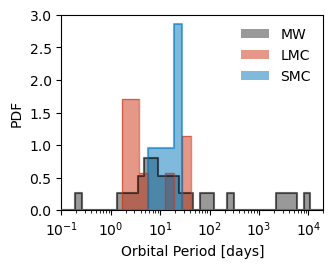

In [4]:
fig, ax = plt.subplots(1,1, figsize=(3.38, 2.535))

plot_observations(obs_df, ax)
# Plot LMC and SMC data
plot_observations_LMC(ax)
plot_observations_SMC(ax)

ax.set_ylim(0, 3)
ax.set_xlim(1e-1, 2e4)

ax.set_xscale('log')
ax.set_xlabel('Orbital Period [days]')
ax.set_ylabel('PDF')

ax.legend(frameon=False)
plt.savefig(FIGURE_DIR / 'pdf' / 'observed_period_distributions.pdf',  bbox_inches='tight')
plt.savefig(FIGURE_DIR / 'png' / 'observed_period_distributions.png',  bbox_inches='tight')